# Discovering What Causes What

*The Mathematics of Machine Intelligence · Chapter 16*

Tell what a thing does when set from what it merely goes along with, and see where a stand-in score fails.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Before using a record to say what a change would do, ask what else could have set both the cause and the effect, whether the cause was assigned by chance or by something that also touches the outcome, and which variable you would actually set. Work the weighted average by hand when a grouping variable is recorded, and treat a stand-in score as a bet that needs the allowed behaviors named.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 16, Discovering What Causes What: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def tiny(value, digits=3):
    """Like sig, but a small nonzero value is never shown as 0: below 0.001 it is written in e-notation (2.82e-13)."""
    value = float(value)
    if value == 0:
        return '0'
    text = f'{value:.{digits}g}'
    if abs(value) >= 0.001 or 'e' not in text:
        return text
    mantissa, exponent = text.split('e')
    return f'{mantissa}e{int(exponent)}'

def pct(value, digits=3):
    """A fraction written as a percent."""
    return sig(100 * value, digits) + ' percent'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.2, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)
HYPOTHESES = ['neither\ntriggers', 'only A\ntriggers', 'only B\ntriggers', 'both\ntrigger']
HYPOTHESIS_TRIGGERS = [(False, False), (True, False), (False, True), (True, True)]
EVENTS = [(False, True, False), (True, False, True), (True, True, True)]
EVENT_NAMES = ['B alone: nothing', 'A alone: lit', 'A and B: lit']

def machine_lit(hypothesis, a_on, b_on):
    """The toy's rule: either triggering block that sits on the machine is enough to light it."""
    trig_a, trig_b = HYPOTHESIS_TRIGGERS[hypothesis]
    return a_on and trig_a or (b_on and trig_b)

def prior_over_hypotheses(p_trigger):
    """Each block independently triggers the machine with chance p (the companion's choice of prior)."""
    q = 1 - p_trigger
    return np.array([q * q, p_trigger * q, q * p_trigger, p_trigger ** 2])

def tally(events_watched, p_trigger):
    """Posterior over the four explanations after the first `events_watched` events, noise-free machine."""
    weights = prior_over_hypotheses(p_trigger).copy()
    for a_on, b_on, lit in EVENTS[:events_watched]:
        for h in range(4):
            if machine_lit(h, a_on, b_on) != lit:
                weights[h] = 0.0
    return weights / weights.sum()

def tally_picture(events_watched=3, p_trigger=0.5):
    post = tally(events_watched, p_trigger)
    prior = prior_over_hypotheses(p_trigger)
    fig, ax = panels()
    colours = [GREY, TEAL, TERRA, GOLD]
    bars = ax[0].bar(HYPOTHESES, post, color=colours, width=0.65)
    ax[0].plot(range(4), prior, linestyle='none', marker='_', markersize=22, markeredgewidth=2.5, color=NAVY, label="before any event (companion's p)")
    for bar, v in zip(bars, post):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v + 0.03, sig(v), va='bottom')
    ax[0].set(ylabel='chance of each explanation', ylim=(0, 1.15), title=f'After {events_watched} of 3 events')
    ax[0].tick_params(axis='x', labelsize=9)
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2))
    grid = np.array([tally(k, p_trigger) for k in range(4)]).T
    ax[1].imshow(grid, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    for h in range(4):
        for k in range(4):
            ax[1].text(k, h, sig(grid[h, k], 2), ha='center', va='center', fontsize=9, color='white' if grid[h, k] > 0.6 else NAVY)
    ax[1].plot([events_watched], [int(np.argmax(post))], marker='o', markersize=14, markerfacecolor='none', markeredgecolor=GOLD, markeredgewidth=2.6, zorder=6)
    ax[1].set_yticks(range(4), [h.replace('\n', ' ') for h in HYPOTHESES], fontsize=9)
    ax[1].set_xticks(range(4), ['start', 'after 1', 'after 2', 'after 3'], fontsize=9)
    ax[1].set(title='Every stage (circle: shown left)')
    ax[1].grid(False)
    p_stops_a = post[1]
    p_stops_b = post[2]
    metrics = {'Explanations still possible': str(int((post > 0).sum())), 'Chance neither block triggers it': sig(post[0]), 'Chance removing A stops it': sig(p_stops_a), 'Chance removing B stops it': sig(p_stops_b)}
    if events_watched == 0:
        summary = f'Before any event, a block triggers the machine with chance {sig(p_trigger)}, so all four explanations stay open. Nothing yet says which block to take off.'
    else:
        names = '; '.join(EVENT_NAMES[:events_watched])
        summary = f'After the events ({names}), {int((post > 0).sum())} of 4 explanations remain. The chance that taking A off stops the machine is {sig(p_stops_a)} and for B it is {sig(p_stops_b)}.'
    calc = 'Start: weights (1-p)^2, p(1-p), (1-p)p, p^2 with p = ' + sig(p_trigger) + " (the companion's choice of starting chance; the book assigns none): " + ', '.join((sig(x) for x in prior)) + '. Cross out each explanation that clashes with an event, then divide by what is left: ' + ', '.join((sig(x) for x in post)) + '.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def machine_logs(coin_chance):
    """Logged chance of switch on, and of light on given switch on, in both machines (they are identical)."""
    return {'p_switch_on': coin_chance, 'p_light_given_switch': 1.0}

def light_rate_after_setting(machine, switch_value, coin_chance):
    """Chance the light is on after the switch is set by hand, in machine H (hidden coin) or D (switch drives light)."""
    if machine == 'D':
        return float(switch_value)
    if machine == 'H':
        return coin_chance
    raise ValueError('machine must be H or D')

def mimic_chance(coin_chance, trials):
    """Chance that machine H, set on and off by hand with equal numbers of trials per arm, shows exactly
    D's pattern: every set-on trial lit and every set-off trial dark."""
    return (coin_chance * (1 - coin_chance)) ** trials

def setting_picture(coin_chance=0.5, trials=8):
    arms = [('H', 1), ('H', 0), ('D', 1), ('D', 0)]
    expected = [light_rate_after_setting(m, s, coin_chance) for m, s in arms]
    rng = np.random.default_rng(1602)
    observed = []
    for m, s in arms:
        if m == 'H':
            observed.append(float((rng.random(trials) < coin_chance).mean()))
        else:
            observed.append(float(s))
    fig, ax = panels()
    labels = ['H\nset on', 'H\nset off', 'D\nset on', 'D\nset off']
    colours = [TERRA, TERRA, TEAL, TEAL]
    bars = ax[0].bar(labels, expected, color=colours, width=0.62, alpha=0.85)
    ax[0].plot(range(4), observed, linestyle='none', marker='D', markersize=8, color=NAVY, label=f'one seeded run of {trials} trials per arm')
    for bar, v in zip(bars, expected):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, v / 2 if v > 0.2 else v + 0.07, sig(v, 2), va='center' if v > 0.2 else 'bottom', color=NAVY)
    ax[0].set(ylabel='share of days the light is on', ylim=(0, 1.2), title='Light after setting the switch by hand')
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2))
    grid = np.arange(1, 13)
    for q, style, colour in [(0.1, 'dotted', GREY), (0.3, 'dashed', GOLD), (0.5, 'solid', TEAL)]:
        chosen = q == coin_chance
        ax[1].plot(grid, [mimic_chance(q, int(n)) for n in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'coin chance {q:g}')
    ring(ax[1], trials, mimic_chance(coin_chance, trials))
    ax[1].set_yscale('log')
    ax[1].set(xlabel='trials in each arm', ylabel='chance H looks exactly like D', title='More trials separate the machines', ylim=(1e-14, 2))
    ax[1].legend(fontsize=9, loc='lower left')
    mimic = mimic_chance(coin_chance, trials)
    metrics = {'Logged chance of light when switch on (both)': '1', 'Light after set on, H': sig(expected[0]), 'Light after set on, D': sig(expected[2]), 'Chance H mimics D in the experiment': tiny(mimic)}
    tiny_note = ' (tiny, but not zero)' if mimic < 1e-06 else ''
    summary = f"In both logs the light was on whenever the switch was. Set by hand, the light comes on {sig(expected[0])} of the time in H and always in D. With {trials} trials per arm, H shows D's exact pattern by luck with chance {tiny(mimic)}{tiny_note}."
    calc = f'H: the hidden coin lights the light with chance {sig(coin_chance)} whatever the setting. D: the light follows the setting. Mimic chance = (c x (1 - c))^n = ({sig(coin_chance)} x {sig(1 - coin_chance)})^{trials} = {tiny(mimic)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
RATE_SMOKER = {'carrier': 0.2, 'noncarrier': 0.04}
RATE_NONSMOKER = {'carrier': 0.1, 'noncarrier': 0.02}
NONCARRIER_SMOKING = 0.2

def backdoor(carrier_share, carrier_smoking, noncarrier_smoking=NONCARRIER_SMOKING, rate_smoker=RATE_SMOKER, rate_nonsmoker=RATE_NONSMOKER):
    """Raw comparison of smokers with nonsmokers, and the back-door average over carrier groups."""
    g = carrier_share
    smokers_carrier = g * carrier_smoking
    smokers_non = (1 - g) * noncarrier_smoking
    nonsmokers_carrier = g * (1 - carrier_smoking)
    nonsmokers_non = (1 - g) * (1 - noncarrier_smoking)
    raw_smoker = (smokers_carrier * rate_smoker['carrier'] + smokers_non * rate_smoker['noncarrier']) / (smokers_carrier + smokers_non)
    raw_nonsmoker = (nonsmokers_carrier * rate_nonsmoker['carrier'] + nonsmokers_non * rate_nonsmoker['noncarrier']) / (nonsmokers_carrier + nonsmokers_non)
    adj_smoker = g * rate_smoker['carrier'] + (1 - g) * rate_smoker['noncarrier']
    adj_nonsmoker = g * rate_nonsmoker['carrier'] + (1 - g) * rate_nonsmoker['noncarrier']
    return {'raw_smoker': raw_smoker, 'raw_nonsmoker': raw_nonsmoker, 'raw_ratio': raw_smoker / raw_nonsmoker, 'adj_smoker': adj_smoker, 'adj_nonsmoker': adj_nonsmoker, 'adj_ratio': adj_smoker / adj_nonsmoker}

def backdoor_picture(carrier_smoking=0.8, carrier_share=0.3):
    d = backdoor(carrier_share, carrier_smoking)
    fig, ax = panels()
    groups = ['everyone\nlumped', 'carriers', 'non-\ncarriers', 'weighted\naverage']
    smokers = [d['raw_smoker'], RATE_SMOKER['carrier'], RATE_SMOKER['noncarrier'], d['adj_smoker']]
    nons = [d['raw_nonsmoker'], RATE_NONSMOKER['carrier'], RATE_NONSMOKER['noncarrier'], d['adj_nonsmoker']]
    x = np.arange(4)
    ax[0].bar(x - 0.19, [100 * v for v in smokers], 0.36, color=TERRA, label='smokers')
    ax[0].bar(x + 0.19, [100 * v for v in nons], 0.36, color=TEAL, label='nonsmokers')
    for i in range(4):
        tag(ax[0], i - 0.19, 100 * smokers[i] + 0.4, sig(100 * smokers[i], 2), va='bottom', fontsize=8)
        tag(ax[0], i + 0.19, 100 * nons[i] + 0.4, sig(100 * nons[i], 2), va='bottom', fontsize=8)
    ax[0].set_xticks(x, groups, fontsize=9)
    ax[0].set(ylabel='cancer rate (percent)', title='Lumped, within groups, then averaged', ylim=(0, 26))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2)
    grid = np.linspace(0.2, 0.95, 60)
    for g, style, colour in [(0.1, 'dotted', GREY), (0.3, 'solid', TEAL), (0.5, 'dashed', TERRA)]:
        chosen = g == carrier_share
        ax[1].plot(grid, [backdoor(g, s)['raw_ratio'] for s in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'carrier share {g:g}')
    ax[1].axhline(2, color=GOLD, linewidth=2, linestyle='dashed')
    tag(ax[1], 0.62, 2.12, 'adjusted ratio: 2 at every setting', fontsize=9, va='bottom', color=DARK_GOLD)
    ring(ax[1], carrier_smoking, d['raw_ratio'])
    ax[1].set(xlabel='share of carriers who smoke', ylabel='risk ratio, smokers to nonsmokers', title='Raw ratio against adjusted', ylim=(1.5, 8))
    ax[1].legend(fontsize=9, loc='upper left')
    metrics = {'Raw risk ratio': sig(d['raw_ratio']), 'Adjusted risk ratio': sig(d['adj_ratio']), 'Adjusted rate, smokers (percent)': sig(100 * d['adj_smoker']), 'Adjusted rate, nonsmokers (percent)': sig(100 * d['adj_nonsmoker'])}
    summary = f"When {pct(carrier_smoking, 2)} of carriers and {pct(NONCARRIER_SMOKING, 2)} of noncarriers smoke, lumping everyone gives smokers {pct(d['raw_smoker'])} against {pct(d['raw_nonsmoker'])}, a ratio of {sig(d['raw_ratio'])}. Comparing inside each gene group and weighting by group size gives {pct(d['adj_smoker'])} against {pct(d['adj_nonsmoker'])}, a ratio of {sig(d['adj_ratio'])}."
    calc = f"Adjusted smokers = {sig(carrier_share)} x 20 + {sig(1 - carrier_share)} x 4 = {sig(100 * d['adj_smoker'])} percent. Adjusted nonsmokers = {sig(carrier_share)} x 10 + {sig(1 - carrier_share)} x 2 = {sig(100 * d['adj_nonsmoker'])} percent. Raw smokers weight carriers by {sig(carrier_share)} x {sig(carrier_smoking)} against {sig(1 - carrier_share)} x {sig(NONCARRIER_SMOKING)}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def cornfield_least_prevalence(risk_ratio, nonsmoker_prevalence):
    """Least share of smokers who must carry a single yes-or-no trait for it to explain a risk ratio alone.
    Returns None when the required share would exceed 1, which no trait can reach."""
    required = risk_ratio * nonsmoker_prevalence
    return None if required > 1 + 1e-12 else required

def cornfield_picture(risk_ratio=9, nonsmoker_prevalence=0.05):
    required = cornfield_least_prevalence(risk_ratio, nonsmoker_prevalence)
    fig, ax = panels()
    if required is None:
        ax[0].bar(['nonsmokers', 'smokers (needed)'], [100 * nonsmoker_prevalence, 100 * risk_ratio * nonsmoker_prevalence], color=[TEAL, TERRA], width=0.55)
        ax[0].axhline(100, color=NAVY, linewidth=2, linestyle='dashed')
        tag(ax[0], 0.5, 100, '100 percent is the ceiling', fontsize=9, va='bottom', color=NAVY)
        ax[0].set(ylabel='share with the trait (percent)', title='Needed share passes 100 percent', ylim=(0, max(110, 100 * risk_ratio * nonsmoker_prevalence * 1.15)))
        tag(ax[0], 1, 100 * risk_ratio * nonsmoker_prevalence * 0.5, 'impossible', fontsize=12, color='white')
    else:
        bars = ax[0].bar(['nonsmokers', 'smokers (at least)'], [100 * nonsmoker_prevalence, 100 * required], color=[TEAL, TERRA], width=0.55)
        for bar, v in zip(bars, [nonsmoker_prevalence, required]):
            tag(ax[0], bar.get_x() + bar.get_width() / 2, 100 * v + 2, sig(100 * v, 3), va='bottom')
        ax[0].set(ylabel='share with the trait (percent)', title='The trait must be this much more common', ylim=(0, 110))
    grid = np.linspace(0, 0.5, 200)
    for rr, style, colour in [(2, 'dotted', GREY), (5, 'dashed', GOLD), (9, 'solid', TEAL), (20, 'dashed', TERRA)]:
        chosen = rr == risk_ratio
        ax[1].plot(grid, np.minimum(rr * grid, 1.0), color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'risk ratio {rr:g}')
    ax[1].axhline(1, color=GREY, linewidth=1)
    if required is not None:
        ring(ax[1], nonsmoker_prevalence, required)
    else:
        ax[1].plot([nonsmoker_prevalence], [1.0], marker='X', markersize=12, color=NAVY)
    ax[1].set(xlabel='share of nonsmokers with the trait', ylabel='least share of smokers (cap: 1)', title='A rarer trait is easier to believe', ylim=(0, 1.08), xlim=(0, 0.5))
    ax[1].legend(fontsize=9, loc='lower right')
    if required is None:
        need = 'impossible (it would be above 100 percent)'
        summary = f'A risk ratio of {risk_ratio:g} with {pct(nonsmoker_prevalence, 2)} of nonsmokers carrying the trait would need {pct(risk_ratio * nonsmoker_prevalence)} of smokers to carry it. No share can pass 100 percent, so a single yes-or-no trait this common cannot account for the whole association.'
    else:
        need = pct(required, 3)
        summary = f'A risk ratio of {risk_ratio:g} means a trait standing in for smoking must be at least {risk_ratio:g} times as common among smokers. With {pct(nonsmoker_prevalence, 2)} of nonsmokers having it, at least {need} of smokers would have to.'
    metrics = {'Observed risk ratio': sig(risk_ratio), 'Nonsmokers with the trait': pct(nonsmoker_prevalence, 2), 'Smokers who would need it': need}
    calc = f'Least prevalence among smokers = risk ratio x prevalence among nonsmokers = {risk_ratio:g} x {sig(nonsmoker_prevalence)} = {sig(risk_ratio * nonsmoker_prevalence)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
RACE_FEW = ('race, few hits', 1.0, 2.0)
RACE_MANY = ('race, many hits', 1.0, 4.0)
IDLE = ('idle', 0.0, 0.0)
ALLOWED_NAMES = {1: 'two racing behaviors', 2: 'racing plus idle', 3: 'plus circling the lagoon', 4: 'plus any mixture of them'}

def behaviors_for(allowed, lagoon_hits):
    lagoon = ('lagoon', 0.0, float(lagoon_hits))
    base = [RACE_FEW, RACE_MANY]
    if allowed >= 2:
        base.append(IDLE)
    if allowed >= 3:
        base.append(lagoon)
    return base

def opposite_pair(behaviors):
    """A pair where the stand-in score strictly rises while the real score strictly falls, or None."""
    for a in behaviors:
        for b in behaviors:
            if a[2] < b[2] and a[1] > b[1]:
                return (a, b)
    return None

def collinear(points, tol=1e-09):
    pts = np.array([(p[2], p[1]) for p in points], dtype=float)
    base = pts[0]
    diffs = pts[1:] - base
    for i in range(len(diffs)):
        for j in range(i + 1, len(diffs)):
            if abs(diffs[i][0] * diffs[j][1] - diffs[i][1] * diffs[j][0]) > tol:
                return False
    return True

def hackable(allowed, lagoon_hits):
    """Hackable under the definition: some allowed pair of behaviors (or mixtures, at level 4) where raising
    the stand-in score strictly lowers the real score."""
    behaviors = behaviors_for(min(allowed, 3), lagoon_hits)
    if allowed <= 3:
        return opposite_pair(behaviors) is not None
    if not collinear(behaviors):
        return True
    return opposite_pair(behaviors) is not None

def hack_picture(allowed=3, lagoon_hits=10):
    behaviors = behaviors_for(min(allowed, 3), lagoon_hits)
    pair = opposite_pair(behaviors) if allowed <= 3 else None
    is_hack = hackable(allowed, lagoon_hits)
    fig, ax = panels()
    everything = behaviors_for(3, lagoon_hits)
    xs = [b[2] for b in everything]
    ax[0].scatter(xs, [b[1] for b in everything], s=70, facecolors='none', edgecolors=GREY, zorder=3)
    if allowed == 4:
        pts = np.array([(b[2], b[1]) for b in behaviors])
        from_hull = sorted(set(map(tuple, pts)))
        hull = _convex_hull(from_hull)
        if len(hull) >= 3:
            ax[0].fill([p[0] for p in hull], [p[1] for p in hull], color=GOLD, alpha=0.25, zorder=1)
    ax[0].scatter([b[2] for b in behaviors], [b[1] for b in behaviors], s=80, color=TEAL, zorder=4)
    offsets = {'race, few hits': (-0.35, 0.0, 'right'), 'race, many hits': (0.0, 0.1, 'center'), 'idle': (0.0, 0.1, 'center'), 'lagoon': (0.0, -0.14, 'center')}
    for name, real, proxy in everything:
        dx, dy, align = offsets[name]
        tag(ax[0], proxy + dx, real + dy, name, fontsize=8, va='center', ha=align, color=NAVY if (name, real, proxy) in behaviors else GREY)
    if pair:
        (_, r1, p1), (_, r2, p2) = pair
        ax[0].annotate('', xy=(p2, r2), xytext=(p1, r1), arrowprops={'arrowstyle': '->', 'color': TERRA, 'linewidth': 2.2})
    ax[0].set(xlabel='stand-in score (target hits)', ylabel='real goal (race finished)', title=f'Allowed: {ALLOWED_NAMES[allowed]}', ylim=(-0.3, 1.45), xlim=(-5.0, max(14, lagoon_hits + 4)))
    grid_l = [0, 2, 3, 6, 10, 14]
    table = np.array([[1.0 if hackable(a, l) else 0.0 for l in grid_l] for a in (1, 2, 3, 4)])
    ax[1].imshow(table, cmap='Reds', vmin=0, vmax=1.4, aspect='auto')
    for i in range(4):
        for j in range(len(grid_l)):
            ax[1].text(j, i, 'hack' if table[i, j] else 'safe', ha='center', va='center', fontsize=8, color='white' if table[i, j] else NAVY)
    ax[1].set_xticks(range(len(grid_l)), [str(l) for l in grid_l], fontsize=9)
    ax[1].set_yticks(range(4), ['two racing', 'racing, idle', '+ lagoon', '+ mixtures'], fontsize=9)
    ax[1].set(xlabel='target hits from circling the lagoon', title='Safe or hackable (hack), every case')
    ax[1].grid(False)
    if lagoon_hits in grid_l:
        ring(ax[1], grid_l.index(lagoon_hits), allowed - 1)
    if pair:
        offending = f'{pair[0][0]} to {pair[1][0]}'
    elif is_hack:
        offending = 'a mixture of behaviors'
    else:
        offending = 'none'
    metrics = {'Pushing the stand-in score': 'can lower the real goal' if is_hack else 'never lowers the real goal', 'Pair that shows it': offending, 'Behaviors allowed': str(len(behaviors)) + (' and all mixtures' if allowed == 4 else '')}
    if pair:
        summary = f'With the allowed set ({ALLOWED_NAMES[allowed]}), moving from {pair[0][0]} ({sig(pair[0][2])} hits) to {pair[1][0]} ({sig(pair[1][2])} hits) raises the stand-in score while the race goes from finished to unfinished. The stand-in is hackable in this made-up set.'
    elif is_hack:
        summary = 'Once any mixture of behaviors is allowed, the stand-in is safe only if the two scores rank every mixture alike or one of them never tells behaviors apart, and neither holds here. Some mixture raises the stand-in score while lowering the real goal.'
    else:
        summary = f'With the allowed set ({ALLOWED_NAMES[allowed]}), no allowed behavior has a higher stand-in score and a lower real score than another, so pushing the score never hurts the goal in this made-up set.'
    calc = 'Real goal = races finished; stand-in = target hits. Behaviors (real, stand-in): ' + '; '.join((f'{b[0]} ({sig(b[1])}, {sig(b[2])})' for b in behaviors)) + '. Hackable if some pair has a higher stand-in score and a lower real score.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def _convex_hull(points):
    pts = sorted(set(points))
    if len(pts) <= 2:
        return pts

    def cross(o, a, b):
        return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])
    lower, upper = ([], [])
    for p in pts:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 0:
            lower.pop()
        lower.append(p)
    for p in reversed(pts):
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 0:
            upper.pop()
        upper.append(p)
    return lower[:-1] + upper[:-1]
N_VARS = 5
PUSH = 4.0
GRAPHS = 100000
LEVEL_BAND = 0.03

def total_effects(weights):
    """Path sums: entry [v, t] is the effect on t of setting v by one unit (weights[i, j] is an edge i to j)."""
    return np.linalg.inv(np.eye(N_VARS) - weights)

def draw_graphs(density, rng, count=GRAPHS):
    mask = np.triu(rng.random((count, N_VARS, N_VARS)) < density, k=1)
    magnitude = rng.uniform(0.5, 1.5, (count, N_VARS, N_VARS))
    sign = rng.choice([-1.0, 1.0], (count, N_VARS, N_VARS))
    return mask * magnitude * sign

def simulate_values(weights, noise, rng, intervene_at=None, value=PUSH):
    """One noisy episode per graph; variables are computed in the graph's order, with one set from outside."""
    count = weights.shape[0]
    x = np.zeros((count, N_VARS))
    eps = rng.normal(0, noise, (count, N_VARS))
    for j in range(N_VARS):
        x[:, j] = np.einsum('gi,gi->g', x, weights[:, :, j]) + eps[:, j]
        if intervene_at is not None and j == intervene_at:
            x[:, j] = value
    return x

@lru_cache(maxsize=None)
def explorer_study(noise, density):
    rng = np.random.default_rng(1616)
    w = draw_graphs(density, rng)
    count = w.shape[0]
    target = rng.integers(0, N_VARS, count)
    effects = np.linalg.inv(np.eye(N_VARS)[None] - w)
    idx = np.arange(count)
    value = PUSH * effects[idx, :, target]
    value[idx, target] = -np.inf
    best_signed = np.max(np.abs(np.where(np.isfinite(value), value, 0.0)), axis=1)
    oracle = best_signed
    seen = np.zeros((count, N_VARS))
    for v in range(N_VARS):
        trial = simulate_values(w, noise, rng, intervene_at=v)
        seen[:, v] = trial[idx, target]
    seen_masked = np.where(np.arange(N_VARS)[None] == target[:, None], 0.0, seen)
    pick = np.argmax(np.abs(seen_masked), axis=1)
    sign = np.sign(seen_masked[idx, pick])
    sign[sign == 0] = 1
    intervening = sign * np.where(np.isfinite(value[idx, pick]), value[idx, pick], 0.0)
    obs = np.stack([simulate_values(w, noise, rng) for _ in range(N_VARS)], axis=1)
    centred = obs - obs.mean(axis=1, keepdims=True)
    cov = np.einsum('gsv,gs->gv', centred, centred[idx, :, target])
    sd = np.sqrt((centred ** 2).sum(axis=1) * (centred[idx, :, target] ** 2).sum(axis=1)[:, None]) + 1e-12
    corr = cov / sd
    corr[idx, target] = 0.0
    pick_obs = np.argmax(np.abs(corr), axis=1)
    sign_obs = np.sign(corr[idx, pick_obs])
    sign_obs[sign_obs == 0] = 1
    watching = sign_obs * np.where(np.isfinite(value[idx, pick_obs]), value[idx, pick_obs], 0.0)
    choice = rng.integers(0, N_VARS - 1, count)
    choice = np.where(choice >= target, choice + 1, choice)
    random_sign = rng.choice([-1.0, 1.0], count)
    guessing = random_sign * value[idx, choice]
    return {'oracle': float(oracle.mean()), 'intervening': float(intervening.mean()), 'watching': float(watching.mean()), 'random': float(guessing.mean())}
AGENT_ORDER = ['oracle', 'intervening', 'watching', 'random']
AGENT_LABELS = {'oracle': 'knows the\ndiagram', 'intervening': 'sets each\nvariable once', 'watching': 'only\nwatches', 'random': 'random\nchoice'}
AGENT_COLOURS = {'oracle': NAVY, 'intervening': TEAL, 'watching': GOLD, 'random': GREY}

def experimenter_picture(noise=1.0, density=0.6):
    res = explorer_study(noise, density)
    fig, ax = panels()
    heights = [res[a] for a in AGENT_ORDER]
    bars = ax[0].bar([AGENT_LABELS[a] for a in AGENT_ORDER], heights, color=[AGENT_COLOURS[a] for a in AGENT_ORDER], width=0.62)
    for bar, h in zip(bars, heights):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, h + 0.05 if h >= 0 else 0.05, sig(h, 3), va='bottom')
    ax[0].axhline(0, color=GREY, linewidth=1)
    ax[0].tick_params(axis='x', labelsize=9)
    ax[0].set(ylabel='average value of the cued variable', title='Rule-based explorers: five steps, one push', ylim=(min(-0.3, min(heights) - 0.2), res['oracle'] * 1.2 + 0.2))
    grid = [0.25, 0.5, 1.0, 2.0, 4.0]
    for agent in AGENT_ORDER[1:]:
        shares = [explorer_study(s, density)[agent] / explorer_study(s, density)['oracle'] for s in grid]
        ax[1].plot(grid, shares, color=AGENT_COLOURS[agent], marker='o', linewidth=2.2, label=AGENT_LABELS[agent].replace('\n', ' '))
    ring(ax[1], noise, res['intervening'] / res['oracle'])
    ring(ax[1], noise, res['watching'] / res['oracle'])
    ax[1].set_xscale('log')
    ax[1].minorticks_off()
    ax[1].set_xticks(grid, [str(g) for g in grid])
    ax[1].axhline(1, color=NAVY, linewidth=1, linestyle='dotted')
    ax[1].set(xlabel='noise sd on every variable', ylabel='share of the best possible value', title='What watching leaves out', ylim=(-0.15, 1.1))
    ax[1].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    metrics = {'Sets each variable once': sig(res['intervening'] / res['oracle']), 'Only watches': sig(res['watching'] / res['oracle']), 'Random choice': sig(res['random'] / res['oracle']), 'Best possible (sampled average value)': sig(res['oracle'])}
    gap = (res['intervening'] - res['watching']) / res['oracle']
    verdict = 'The two are about level here.' if abs(gap) < LEVEL_BAND else 'The setter is ahead here.' if gap > 0 else 'The watcher is ahead here.'
    summary = f"In {GRAPHS:,} random five-variable diagrams (noise sd {noise:g}, edge chance {density:g}), a rule-based explorer that sets each variable once reaches {sig(res['intervening'] / res['oracle'])} of the best value, one that only watches {sig(res['watching'] / res['oracle'])}, and a random pick {sig(res['random'] / res['oracle'])}. {verdict} This is the companion's constructed world, not the paper's networks."
    calc = f"Expected value of setting variable v to +4 or -4 is 4 x (path sum from v to the cue). The best possible is the larger of those over v. Seeded sample averages over {GRAPHS:,} diagrams (sampling error remains in the last digit) give oracle {sig(res['oracle'])}, setters {sig(res['intervening'])}, watchers {sig(res['watching'])}, random {sig(res['random'])}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C16-D01: Which explanations survive three watched events?

Block B alone does nothing, block A alone lights the machine, and A with B keeps it lit. Which of four possible explanations are left, and which block should a child take off?

Each explanation says which blocks trigger the machine. B alone did nothing, which strikes out every explanation where B triggers. A alone lit it, which strikes out 'neither' and any explanation where A fails to trigger. What remains has A as the only trigger. The third event adds nothing, because A already explains the light. The starting chance p changes the in-between chances, not the final answer.

$$
P(h\mid e_1,\dots,e_k)=\frac{P(h)\,[h \text{ fits } e_1,\dots,e_k]}{\sum_{h'} P(h')\,[h' \text{ fits } e_1,\dots,e_k]}
$$

**Symbols:** h: one of four explanations: neither block triggers, only A, only B, or both; e_1 ... e_k: the events watched so far (B alone: nothing; A alone: lit; A and B: lit); P(h): the starting chance of an explanation; here each block triggers with chance p, independently; [h fits e]: 1 if the explanation allows what was seen, 0 if it is crossed out

**Predict before looking:** After only the first event (B alone: nothing), predict whether the toy already points to taking A off or whether it still needs the second event.

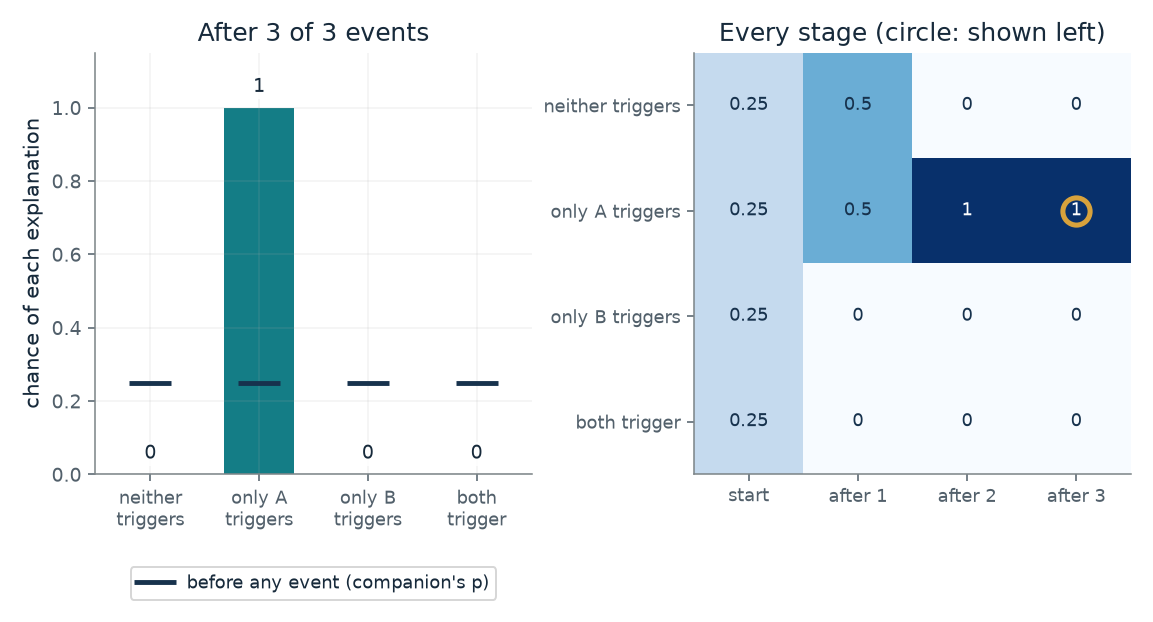

- **Explanations still possible:** 1
- **Chance neither block triggers it:** 0
- **Chance removing A stops it:** 1
- **Chance removing B stops it:** 0

After the events (B alone: nothing; A alone: lit; A and B: lit), 1 of 4 explanations remain. The chance that taking A off stops the machine is 1 and for B it is 0.

Start: weights (1-p)^2, p(1-p), (1-p)p, p^2 with p = 0.5 (the companion's choice of starting chance; the book assigns none): 0.25, 0.25, 0.25, 0.25. Cross out each explanation that clashes with an event, then divide by what is left: 0, 1, 0, 0.

In [2]:
figure, values, explanation = tally_picture(**{'events_watched': 3, 'p_trigger': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Which explanations survive three watched events?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Events watched (0 to 3) = 3, Starting chance a block triggers it (companion's choice) = 0.5: After all three events only one explanation survives, 'only A triggers', so taking A off is the action the toy advises. In the study 18 of 24 children took A off first. Slide back to see that two events already leave one explanation, and the third rules out nothing more.

**Takeaway:** Crossing out explanations that clash with what was seen can leave a single survivor after very few events, and the survivor tells you which block to remove.

**Why it matters:** A system that keeps a list of rival explanations and strikes out the ones the data contradict does a simple form of Bayesian updating, as long as someone supplies the list and the starting chances.

**In brains and behavior:** Eighteen of 24 children took block A off first. The authors say their experiments do not test which account of causal learning explains this, so the tally is not a model of the children.

**In machines:** A program can hold the four explanations and their starting chances and strike out the ones the events contradict. Its starting assumption about the device is supplied by its builder.

**Where it applies:** Each block either triggers the machine on its own or has no effect, either triggering block suffices, and the machine behaves without noise. The tally describes a machine that keeps such a list; the chapter says it does not describe the children, and the authors did not measure a prior distribution.

**Check your understanding:** With p = 0.5, what is the chance that A is a trigger after only the first event?

<details><summary>Show the answer</summary>

B's silence strikes out 'only B' and 'both', leaving 'neither' and 'only A' with weights 0.25 each, so A is a trigger with chance 0.5 (in general p). The second event strikes out 'neither' and A is a trigger for sure.

</details>

*Source: Chapter 16, Three events, four explanations, one block. The chapter's toy tally of four explanations under independent-trigger assumptions, with the events of Gopnik and colleagues (2001). The chapter crosses out explanations without assigning starting chances; the independent trigger chance p is this companion's way of showing the chance version of the same tally. The children's counts (18 of 24 took A off first, 3 took B, 3 took both) are reported in the chapter and are not computed here.*

## C16-D02: Why can identical logs hide different effects of setting a switch?

Two machines keep the same log of a switch and a light. If you set the switch by hand, does the light follow in both?

In both machines the light and the switch are on together or off together, so the logs match. In H a hidden coin decides both, so setting the switch leaves the light to the coin. In D the switch drives the light, so the light follows the setting. Setting the switch on and off at random trials makes the two machines predict different light rates, and more trials make a lucky match less and less likely.

$$
p(y\mid do(x))\ne p(y\mid x)\ \text{in general}
$$

**Symbols:** y: the outcome, here the light; x: the variable, here the switch; do(x): x was set from outside, not merely seen; p(y | x): the chance of y among recorded cases where x had that value

**Predict before looking:** In both logs the light was on every time the switch was on. Predict how often the light comes on in each machine when someone sets the switch on by hand.

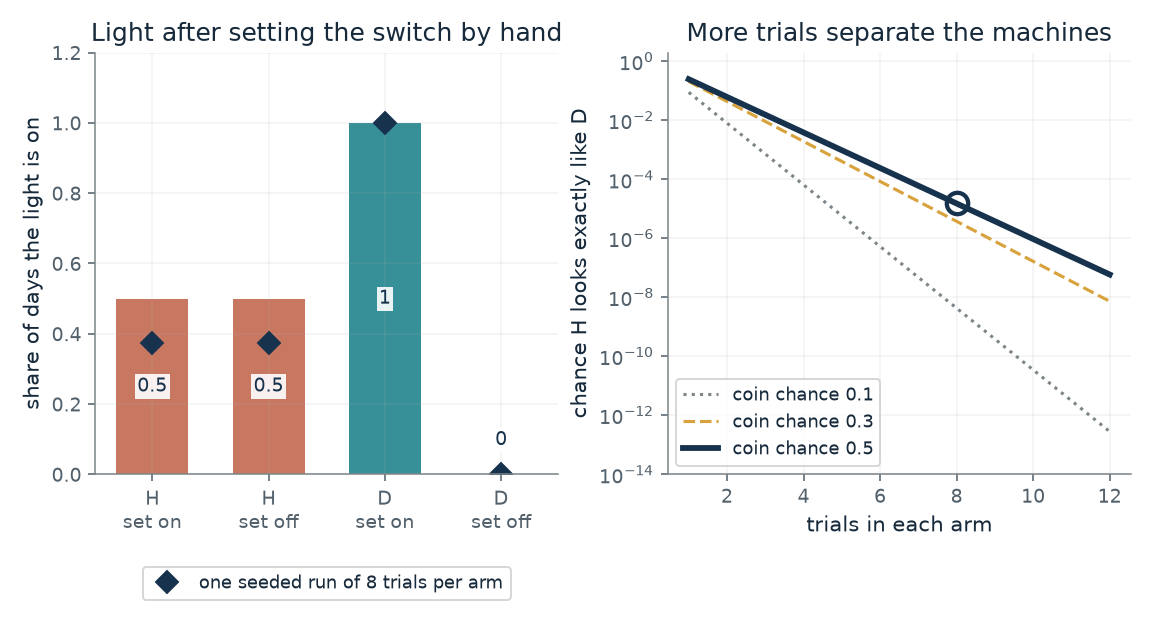

- **Logged chance of light when switch on (both):** 1
- **Light after set on, H:** 0.5
- **Light after set on, D:** 1
- **Chance H mimics D in the experiment:** 1.53e-5

In both logs the light was on whenever the switch was. Set by hand, the light comes on 0.5 of the time in H and always in D. With 8 trials per arm, H shows D's exact pattern by luck with chance 1.53e-5.

H: the hidden coin lights the light with chance 0.5 whatever the setting. D: the light follows the setting. Mimic chance = (c x (1 - c))^n = (0.5 x 0.5)^8 = 1.53e-5.

In [3]:
figure, values, explanation = setting_picture(**{'trials': 8, 'coin_chance': 0.5})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why can identical logs hide different effects of setting a switch?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Trials in each arm = 8, Chance the hidden coin is on (0.5 is the chapter's) = 0.5: Set on by hand, the light is on half the time in H and every time in D, though the logs were identical. With 8 trials in each arm, H shows D's exact pattern by luck with chance about 0.000015 (1.5 in 100,000). A few trials already tell the machines apart.

**Takeaway:** A record answers what goes with what. What setting a variable would do needs a setting, or assumptions that rule out a hidden common cause.

**Why it matters:** A machine that learns only from logs can mistake a switch that merely accompanies the light for one that makes it. Setting the variable on randomly chosen trials separates the two.

**In brains and behavior:** Gopnik and colleagues' machine had a hidden switch worked by an assistant the children never saw. The paper has no data on hidden causes of this kind.

**In machines:** A program can list the rival predictions and count outcomes. A person must decide whether the setting is safe and whether it really isolates the switch.

**Where it applies:** In H a hidden coin sets the switch and the light together and the switch does nothing; in D the coin sets only the switch and the switch sets the light. The experiment assumes setting the switch changes the switch without separately changing the light. The chapter's coin is fair; other chances are this companion's variation.

**Check your understanding:** With a fair coin and 3 trials in each arm, what is the chance that H shows D's exact pattern (all lit when set on, all dark when set off)?

<details><summary>Show the answer</summary>

Set-on trials are all lit with chance 0.5^3 = 0.125 and set-off trials are all dark with chance 0.5^3 = 0.125, so (0.5 x 0.5)^3 = 0.015625, about 1.6 percent.

</details>

*Source: Chapter 16, Seeing is not setting. The chapter's constructed pair of machines, H and D, with a fair hidden coin (the coin chance is varied here). The chapter says explicitly that the pair is made up and not data. The seeded trials are simulated with a fixed seed; the 'mimic chance' is exact arithmetic for the experiment of equal numbers of set-on and set-off trials.*

## C16-D03: How much of a risk ratio is the gene?

Smokers look five times as likely to get cancer when everyone is lumped, but a gene feeds both smoking and cancer. What does adjusting by the gene give?

Smokers are mostly carriers in this example, and carriers have more cancer whether or not they smoke. The raw comparison therefore credits smoking with the gene's effect. The back-door formula compares smokers with nonsmokers inside each group, where the gene cannot differ, and then weights the groups by their share of the population, 0.3 and 0.7 here.

$$
P(Y=y\mid\operatorname{do}(X=x))=\sum_z P(Y=y\mid X=x,Z=z)\,P(Z=z)
$$

**Symbols:** X: the exposure, smoking; Y: the outcome, cancer; Z: the recorded grouping variable, carrying the gene or not; P(Z=z): the share of the whole population in group z (0.3 carriers, 0.7 noncarriers)

**Predict before looking:** If carriers and noncarriers smoked at the same rate (0.2), predict how the raw ratio would compare with the adjusted ratio.

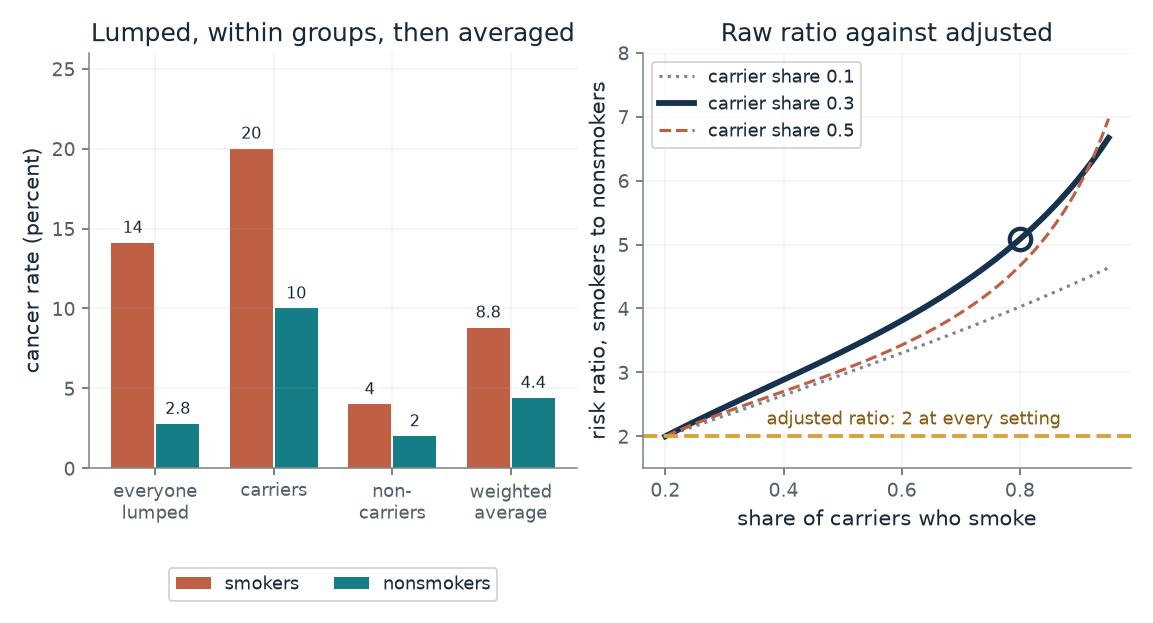

- **Raw risk ratio:** 5.08
- **Adjusted risk ratio:** 2
- **Adjusted rate, smokers (percent):** 8.8
- **Adjusted rate, nonsmokers (percent):** 4.4

When 80 percent of carriers and 20 percent of noncarriers smoke, lumping everyone gives smokers 14.1 percent against 2.77 percent, a ratio of 5.08. Comparing inside each gene group and weighting by group size gives 8.8 percent against 4.4 percent, a ratio of 2.

Adjusted smokers = 0.3 x 20 + 0.7 x 4 = 8.8 percent. Adjusted nonsmokers = 0.3 x 10 + 0.7 x 2 = 4.4 percent. Raw smokers weight carriers by 0.3 x 0.8 against 0.7 x 0.2.

In [4]:
figure, values, explanation = backdoor_picture(**{'carrier_smoking': 0.8, 'carrier_share': 0.3})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much of a risk ratio is the gene?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Share of carriers who smoke = 0.8, Share of people who carry the gene = 0.3: Lumped together, smokers have 14.1 percent and nonsmokers 2.77 percent, a ratio of 5.08. Averaged by group with the same weights, smokers have 8.8 percent and nonsmokers 4.4, a ratio of 2. The gene was feeding the raw gap.

**Takeaway:** The raw gap mixed the effect of smoking with the effect of the gene; comparing inside each group and then averaging with the same weights removes the gene's share.

**Why it matters:** A recorded confounder lets an analyst estimate what setting the exposure would do. The result is only as good as the causal diagram that says the grouping blocks every hidden route.

**In brains and behavior:** Fisher argued in 1957 that a common genetic cause had not been excluded; Cornfield's group answered with a bound and with many lines of evidence. This is a dispute about evidence, not a model of a brain.

**In machines:** A program can compute the weighted average once the grouping variable is recorded and the diagram is stated. It cannot supply the diagram.

**Where it applies:** The gene is recorded, blocks every back-door path, and is not an effect of smoking; smokers and nonsmokers appear in each group. The drawing of the causal diagram is the analyst's assumption, and the formula is only as good as the diagram.

**Check your understanding:** Carriers are 0.3 of the population. Among carriers 20 percent of smokers and 10 percent of nonsmokers get cancer; among noncarriers 4 and 2 percent. What are the adjusted rates?

<details><summary>Show the answer</summary>

Smokers: 0.3 x 20 + 0.7 x 4 = 8.8 percent. Nonsmokers: 0.3 x 10 + 0.7 x 2 = 4.4 percent. The adjusted ratio is 2.

</details>

*Source: Chapter 16, Fisher, Cornfield, and the hidden trait behind smoking. Book formula (Pearl 1995) with the chapter's made-up numbers: 3 in 10 carry the gene; among carriers 20 percent of smokers and 10 percent of nonsmokers get cancer; among noncarriers 4 and 2 percent; 8 in 10 carriers and 2 in 10 noncarriers smoke. The other carrier shares and smoking shares are this companion's variations. None of it is data.*

## C16-D04: How common must a hidden trait be to explain away a risk ratio?

Suppose smoking did nothing and one yes-or-no trait caused the whole association. How common would it have to be among smokers?

If the trait explained everything, the extra risk smokers carry would have to come from smokers having the trait more often. A ninefold risk needs at least a ninefold difference in how often the trait appears. A share cannot exceed 100 percent, so a trait present in more than 1 in 9 nonsmokers cannot reach nine times that among smokers.

$$
\frac{\text{share of smokers with the trait}}{\text{share of nonsmokers with the trait}}\ \ge\ \text{risk ratio}
$$

**Symbols:** risk ratio: how many times likelier the outcome is in smokers than in nonsmokers (9 in the studies the chapter reviews); share of nonsmokers: the share of nonsmokers who have the hypothetical trait; share of smokers: the least share of smokers who would need it

**Predict before looking:** At a risk ratio of 9, predict how common the trait must be among smokers if it appears in 1 nonsmoker in 20, and whether it could exist if it appeared in 1 in 5.

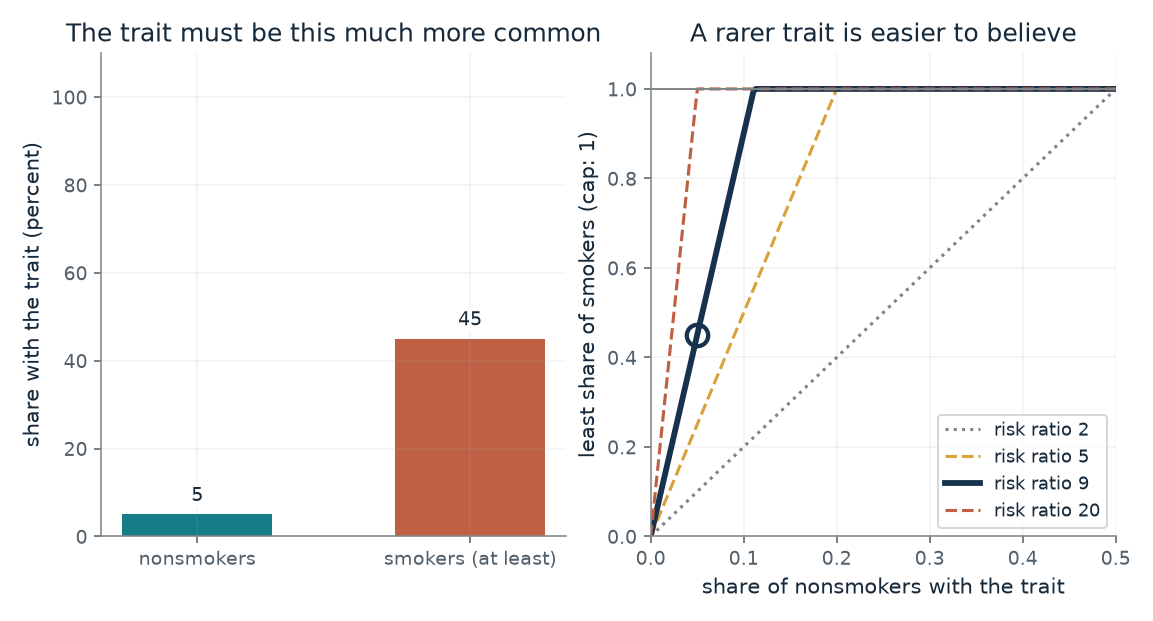

- **Observed risk ratio:** 9
- **Nonsmokers with the trait:** 5 percent
- **Smokers who would need it:** 45 percent

A risk ratio of 9 means a trait standing in for smoking must be at least 9 times as common among smokers. With 5 percent of nonsmokers having it, at least 45 percent of smokers would have to.

Least prevalence among smokers = risk ratio x prevalence among nonsmokers = 9 x 0.05 = 0.45.

In [5]:
figure, values, explanation = cornfield_picture(**{'risk_ratio': 9, 'nonsmoker_prevalence': 0.05})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How common must a hidden trait be to explain away a risk ratio?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Observed risk ratio = 9, Share of nonsmokers with the trait = 0.05: At ratio 9 and 5 percent of nonsmokers, at least 45 percent of smokers (9 in 20) would need the trait. Move the nonsmoker share to 20 percent and the answer passes 100 percent, so no such trait can exist.

**Takeaway:** A strong association sets a hard floor on how common a hidden single trait must be, and a large enough floor rules it out.

**Why it matters:** A hidden-trait objection is a quantitative claim. It can be checked against the size of the association, even when nobody measured the trait.

**In brains and behavior:** This is an argument from a published epidemiological dispute, not a statement about any brain or mind.

**In machines:** A system asked to explain an association by an unmeasured trait can compute the floor and report when it is impossible.

**Where it applies:** A single yes-or-no trait, and the whole association assumed to come from it. The chapter says the authors argued from many lines of evidence and not from the bound alone, and that no such trait 'has yet been produced despite diligent search'.

**Check your understanding:** At a risk ratio of 5 and a trait in 10 percent of nonsmokers, what is the least share among smokers?

<details><summary>Show the answer</summary>

5 x 0.10 = 0.50, so at least half of smokers.

</details>

*Source: Chapter 16, Fisher, Cornfield, and the hidden trait behind smoking. The chapter quotes Cornfield and colleagues (1959): a trait that explained the ninefold risk would be 'at least ninefold more prevalent among cigarette smokers than among nonsmokers', and gives the round illustration of 1 in 20 and 9 in 20. The other risk ratios and prevalences are this companion's variations of the same rule.*

## C16-D05: When is it safe to push a stand-in score?

A boat-racing game scores target hits, but the goal is to finish. Which sets of allowed behaviors let pushing the score hurt the goal?

The real goal is finishing and the stand-in is target hits. Among the racing behaviors, more hits never means finishing less, so pushing hits is safe. Add a behavior that never finishes but collects many hits and you can raise the stand-in score by giving up the race. Allow mixtures and the scores must agree on every mixture (or one of them must never tell behaviors apart), which these two cannot do.

$$
\text{hackable if there are behaviors } \pi,\pi' \text{ with } J_{\text{stand-in}}(\pi)<J_{\text{stand-in}}(\pi') \text{ and } J_{\text{real}}(\pi)>J_{\text{real}}(\pi')
$$

**Symbols:** J_real: the real goal's score for a behavior (here 1 if the race is finished, 0 if not); J_stand-in: the stand-in score for a behavior (here target hits); pi, pi': two behaviors the agent is allowed to use

**Predict before looking:** With only the two racing behaviors allowed, predict whether pushing the hit count can ever hurt the race. Then predict what circling the lagoon needs to be worth to change that.

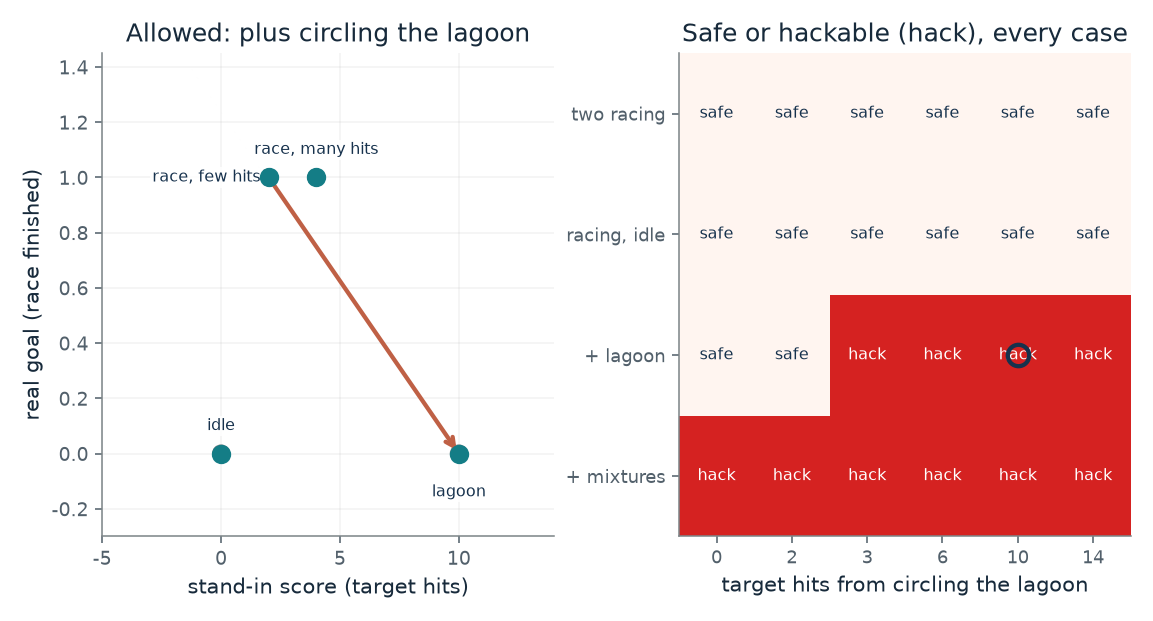

- **Pushing the stand-in score:** can lower the real goal
- **Pair that shows it:** race, few hits to lagoon
- **Behaviors allowed:** 4

With the allowed set (plus circling the lagoon), moving from race, few hits (2 hits) to lagoon (10 hits) raises the stand-in score while the race goes from finished to unfinished. The stand-in is hackable in this made-up set.

Real goal = races finished; stand-in = target hits. Behaviors (real, stand-in): race, few hits (1, 2); race, many hits (1, 4); idle (0, 0); lagoon (0, 10). Hackable if some pair has a higher stand-in score and a lower real score.

In [6]:
figure, values, explanation = hack_picture(**{'allowed': 3, 'lagoon_hits': 10})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='When is it safe to push a stand-in score?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Behaviors allowed (1 to 4) = 3, Target hits from circling the lagoon = 10: With the lagoon allowed and worth 10 hits, circling beats both racing behaviors on the stand-in score while never finishing the race, so the stand-in is hackable. With only racing behaviors it was safe; with the lagoon worth 2 hits or fewer it stays safe until mixtures are allowed.

**Takeaway:** Whether a stand-in is safe depends on which behaviors are allowed, and allowing every mixture of behaviors makes it safe only when the two scores rank everything alike or one of them never tells any behaviors apart.

**Why it matters:** A score that moved with the goal in the cases anyone watched can part ways with it as soon as an optimizer finds a case nobody watched. Naming the allowed behaviors is part of checking a stand-in.

**In brains and behavior:** The chapter brings in Goodhart and Strathern as arguments about audit and economic data, not measurements, and not about brains.

**In machines:** The OpenAI post reports the agent's lagoon behavior and an average score 20 percent above human players, with no algorithm and no raw scores. Skalse and colleagues prove results for simple, finite settings only.

**Where it applies:** A short list of behaviors with fixed real and stand-in scores, checked against the chapter's definition by comparing pairs. At the last setting mixtures are allowed, and a mixture's score is the average of its parts. This is not the finite-policy theorem, whose conditions the chapter states without proof, and it makes no claim about any deployed system.

**Check your understanding:** The lagoon is worth 2 hits and only the finite list of four behaviors is allowed. Is pushing the stand-in score safe?

<details><summary>Show the answer</summary>

Yes. The lagoon's 2 hits do not strictly exceed the 2 hits of the lowest-scoring racing behavior, so no allowed pair has a higher stand-in score and a lower real score.

</details>

*Source: Chapter 16, When pushing a stand-in score backfires. The CoastRunners account (Amodei and Clark, 2016: the game scores target hits, the agent circled a lagoon, 'on average 20 percent higher than that achieved by human players') and the definition and result of Skalse and colleagues (2022) as the chapter states them. The behaviors and their scores (finish with 2 or 4 hits, idle, circle with a chosen number of hits) are made up by this companion; the post gives no raw scores.*

## C16-D06: How much does being allowed to set variables help an agent?

An agent has five steps to explore a five-variable world, then is told which variable to push as high as possible. Does setting variables beat only watching?

Setting a variable breaks any hidden reason it would otherwise move with the cue, so the cue's response to the setting is a direct reading of that variable's effect. Watching mixes direct effects with shared causes and with chance, and five episodes are few. Noise blurs the setter's single reading of the cue, so its advantage shrinks as the noise approaches the push. Scaling every variable's noise together leaves the watcher's correlations unchanged, so its share stays flat.

$$
\mathbb{E}\left[X_t\mid \operatorname{do}(X_v=a)\right]=a\,P_{vt},\qquad P=(I-W)^{-1}
$$

**Symbols:** X_t: the cued variable; a: the value an agent sets for variable v (plus or minus 4); W: edge weights of the world's diagram (entry i, j is the weight of an edge from i to j); P_{vt}: the sum over all paths from v to t of the product of edge weights; the effect of setting v by one unit on t

**Predict before looking:** The setter pushes each variable by 4 and the noise sd starts at 1. Predict whether the setter still beats the watcher when the noise sd rises to 4, the size of the push.

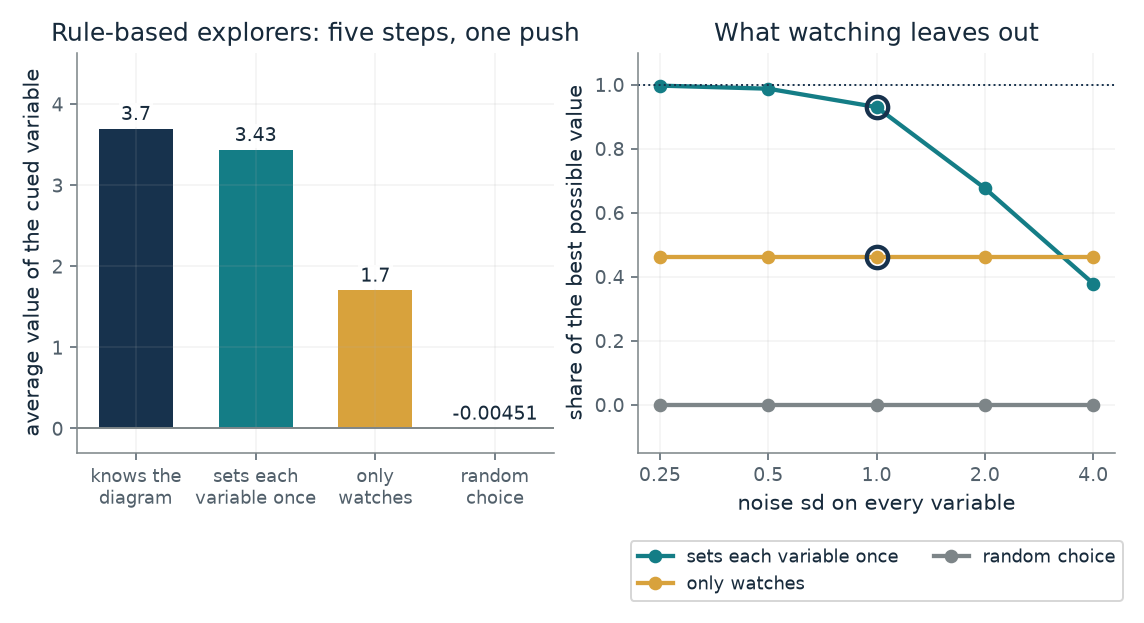

- **Sets each variable once:** 0.93
- **Only watches:** 0.46
- **Random choice:** -0.00122
- **Best possible (sampled average value):** 3.7

In 100,000 random five-variable diagrams (noise sd 1, edge chance 0.6), a rule-based explorer that sets each variable once reaches 0.93 of the best value, one that only watches 0.46, and a random pick -0.00122. The setter is ahead here. This is the companion's constructed world, not the paper's networks.

Expected value of setting variable v to +4 or -4 is 4 x (path sum from v to the cue). The best possible is the larger of those over v. Seeded sample averages over 100,000 diagrams (sampling error remains in the last digit) give oracle 3.7, setters 3.43, watchers 1.7, random -0.00451.

In [7]:
figure, values, explanation = experimenter_picture(**{'noise': 1.0, 'density': 0.6})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much does being allowed to set variables help an agent?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Noise sd on every variable = 1.0, Chance of an edge between two variables = 0.6: At noise sd 1 and edge chance 0.6 the setter reaches about 0.93 of the best value, the watcher about 0.46 and a random choice about 0 (best value about 3.7, a sample average). Turn the noise up to 4, the size of the push, and the setter falls to about 0.38, below the watcher, whose share does not change with noise. At edge chance 0.9 the two end up about level instead.

**Takeaway:** In this constructed world, trying each variable once reads off what each does to the cue far better than watching, but the lead shrinks as the noise nears the push. At noise 4 (the size of the push) the watcher is ahead at edge chance 0.3 and 0.6, and the two are about level at 0.9.

**Why it matters:** The chapter reports that agents trained on an expert's records learned to experiment, and that this worked when the agent could act at test time and much less well when it could only watch. This computation illustrates why watching reads cause less directly, and that setting needs a push that stands out from the noise.

**In brains and behavior:** No brain recording is involved. The only link to the children is that taking a block off is an intervention a child can attempt and a log cannot.

**In machines:** In the paper, imitation-trained networks reached close to the best reward on a held-out causal link only when they could intervene at test time. The explorers here are rule-based stand-ins, not those networks.

**Where it applies:** Random linear diagrams with no loops, edge weights of size 0.5 to 1.5 and either sign, equal noise on every variable, and a cued variable that cannot itself be set. The setter pushes each variable once; the watcher takes five unforced episodes and follows the strongest correlation with the cue. A simulation is a computation with disclosed seeds, never a measurement of an agent.

**Check your understanding:** In a world with one edge, from A to B with weight 1.5, what value of B is expected after setting A to +4, and after setting A to -4?

<details><summary>Show the answer</summary>

Setting A to +4 gives 1.5 x 4 = 6 for B, and setting A to -4 gives -6. The agent that learns which way A pushes B can choose the sign.

</details>

*Source: Chapter 16, Agents that copy an expert who experimented. A constructed, seeded simulation (seed 1616, 100,000 random diagrams per setting, sample averages) in the spirit of the setup the chapter describes from Lampinen and colleagues (2023): five variables, five exploratory steps, settings of plus or minus 4, a cue naming the variable to push. The edge weights, noise and the rule-based explorers are this companion's; the paper's agents were trained networks and the chapter gives no percent of optimal for them.*

## Bring it to your own question

Before using a record to say what a change would do, ask what else could have set both the cause and the effect, whether the cause was assigned by chance or by something that also touches the outcome, and which variable you would actually set. Work the weighted average by hand when a grouping variable is recorded, and treat a stand-in score as a bet that needs the allowed behaviors named.

Use the `mmi-ch16-discovering-causes` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.